# 03. CLARIS: Subgroup Drift & Equidade Algorítmica (Adult Census Income)

Benchmark de **Fairness e Monitoramento de Subpopulações** do projeto CLARIS utilizando dados sociodemográficos reais do censo (**Adult Income**).

### Objetivos e Destaques Metodológicos:
1. **Ingestão Confiável & Tratamento Categórico:** Carga e pré-processamento de atributos sociodemográficos reais (idade, escolaridade, ocupação, carga horária, atributos protegidos).
2. **Auditoria de Equidade no Espaço Latente ($S_{conf}$):** Mapeamento via SHAP para verificar como atributos protegidos afetam a fronteira de decisão e a distância para a aprovação (>50K).
3. **Detecção de Disparidade Contrafactual:**
   - O `DeltaExtractor` isola as variáveis com **maior divergência absoluta em relação ao centróide de alta renda**.
   - Inspeção de viés: verificar se a trajetória contrafactual exige esforços desproporcionais entre subgrupos demográficos distintos.
4. **Visualização 2D com Estratificação de Subgrupo:** Projeção PCA do espaço latente colorindo ou segmentando por atributos protegidos para revelar assimetrias de densidade.
5. **Síntese Factual com Dossiê de Compliance & Equidade:** Análise via Gemini (temperatura zero) fundamentada na legislação de trabalho, mobilidade socioeconômica e governança de IA.
6. **Monitoramento de Subgroup Drift (MLOps):** Simulação de um fluxo de inferências com desbalanço populacional para validar o alerta de degradação.

In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import train_test_split
from IPython.display import display, Markdown
from dotenv import load_dotenv

load_dotenv()

# Configuração de caminhos do projeto
project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if project_root not in sys.path:
    sys.path.insert(0, project_root)

from claris.xai.explainer import ModelExplainer
from claris.cbr.populate_db import initialize_vector_database
from claris.analytics.extractor import DeltaExtractor
from claris.nlg.llm_adapter import LLMAdapter
from claris.mlops.drift_monitor import DriftMonitor

warnings.filterwarnings('ignore', category=UserWarning)
print('✓ Módulos do CLARIS e dependências carregados!')

/root/claris/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


✓ Módulos do CLARIS e dependências carregados!


## 1. Ingestão e Pré-processamento dos Dados Sociodemográficos (Adult Census)

In [2]:
import os
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

print("A carregar dataset sociodemográfico Adult Census...")

df_adult = None

# Tentativa 1: Hugging Face (repositório mstz/adult ou scikit-learn)
try:
    from datasets import load_dataset
    dataset_hf = load_dataset("mstz/adult", split="train")
    df_adult = dataset_hf.to_pandas()
except Exception:
    try:
        from datasets import load_dataset
        dataset_hf = load_dataset("scikit-learn/adult-census-income", split="train")
        df_adult = dataset_hf.to_pandas()
    except Exception:
        pass

# Tentativa 2: Espelhos públicos em CSV direto caso a biblioteca datasets falhe
if df_adult is None:
    urls = [
        "https://raw.githubusercontent.com/selva86/datasets/master/adult.csv",
        "https://raw.githubusercontent.com/amankharwal/Website-data/master/adult.csv",
        "https://raw.githubusercontent.com/jphall663/interpretable_machine_learning_with_python/master/data/adult.csv"
    ]
    for url in urls:
        try:
            df_adult = pd.read_csv(url)
            break
        except Exception:
            continue

if df_adult is None:
    raise RuntimeError("Não foi possível carregar o dataset Adult Census. Verifique a ligação de rede.")

df_adult.columns = df_adult.columns.str.strip().str.lower()

# Localização automática do target de renda (>50K vs <=50K)
target_col = None
candidatos_alvo = ["income", "target", "salary", "class", "label", "over_50k"]

for col in candidatos_alvo:
    if col in df_adult.columns:
        target_col = col
        break

if target_col is None:
    target_col = df_adult.columns[-1]

print(f"✓ Coluna alvo identificada: '{target_col}'")

# Mapeamento binário do alvo (1 = >50K, 0 = <=50K)
y_raw = df_adult[target_col].astype(str).str.strip().str.replace('.', '', regex=False)
y = y_raw.map({'1': 1, '0': 0, '>50k': 1, '<=50k': 0, 'true': 1, 'false': 0}).fillna(0).astype(int).values

X_df = df_adult.drop(columns=[target_col])

# Fatorização das variáveis categóricas para manter atributos numéricos legíveis
for col in X_df.select_dtypes(include=['object', 'category']).columns:
    X_df[col] = pd.factorize(X_df[col].astype(str).str.strip())[0]

feature_names = list(X_df.columns)
X_clean = X_df.apply(pd.to_numeric, errors='coerce').fillna(X_df.median()).values.astype(np.float32)

# Divisão estratificada de treino e teste
X_train, X_test, y_train, y_test = train_test_split(
    X_clean, y, test_size=0.2, random_state=42, stratify=y
)

print(f"✓ Amostras prontas: {len(X_train)} treino | {len(X_test)} teste | {len(feature_names)} atributos.")
print(f"Proporção de Renda Elevada (>50K): {y.mean():.1%}")
df_adult.head(3)

A carregar dataset sociodemográfico Adult Census...


✓ Coluna alvo identificada: 'over_threshold'
✓ Amostras prontas: 9768 treino | 2443 teste | 13 atributos.
Proporção de Renda Elevada (>50K): 23.9%


/tmp/ipykernel_107975/3238818963.py:63: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in X_df.select_dtypes(include=['object', 'category']).columns:


,age,capital_gain,capital_loss,education,final_weight,hours_worked_per_week,marital_status,native_country,occupation,race,relationship,is_male,workclass,over_threshold
0,30,0.0,2258.0,10,257295,40,Never-married,South,Sales,Asian-Pac-Islander,Other-relative,True,Self-emp-not-inc,0
1,38,0.0,0.0,9,208358,40,Married-civ-spouse,United-States,Craft-repair,White,Husband,True,Private,1
2,30,0.0,0.0,9,312767,40,Never-married,United-States,Sales,Black,Unmarried,False,State-gov,0


## 2. Dicionário Semântico Sociodemográfico & Atributos de Equidade

In [3]:
ADULT_SEMANTIC_DICT = {
    # Nomes das colunas presentes no seu DataFrame atual
    'age': 'Idade do Indivíduo (anos)',
    'capital_gain': 'Ganhos de Capital Financeiro ($)',
    'capital_loss': 'Perdas de Capital Financeiro ($)',
    'education': 'Grau de Escolaridade Formulado',
    'final_weight': 'Peso Amostral Ponderado no Censo',
    'hours_worked_per_week': 'Jornada Semanal de Trabalho (horas)',
    'marital_status': 'Estado Civil',
    'native_country': 'País de Origem',
    'occupation': 'Ocupação Profissional',
    'race': 'Cor / Raça Declarada',
    'relationship': 'Papel de Relacionamento Familiar',
    'is_male': 'Sexo Biológico Masculino (Atributo Protegido)',
    'workclass': 'Regime e Setor de Trabalho',
    'over_threshold': 'Renda Superior a 50K Anuais',
    
    # Mapeamento para formatos clássicos da UCI / Fallbacks
    'sex': 'Sexo Biológico (Atributo Protegido)',
    'fnlwgt': 'Peso Amostral Ponderado no Censo',
    'education-num': 'Nível de Escolaridade em Anos Cumpridos',
    'education_num': 'Nível de Escolaridade em Anos Cumpridos',
    'capital-gain': 'Ganhos de Capital Financeiro ($)',
    'capital-loss': 'Perdas de Capital Financeiro ($)',
    'hours-per-week': 'Jornada Semanal de Trabalho (horas)',
    'marital-status': 'Estado Civil',
    'native-country': 'País de Origem'
}

## 3. Treino do Modelo e Construção do $S_{conf}$ no Banco Vetorial

In [4]:
model = GradientBoostingClassifier(n_estimators=50, max_depth=3, random_state=42)
model.fit(X_train, y_train)
acc = model.score(X_test, y_test)
print(f'Modelo treinado. Acurácia preditiva no teste: {acc:.2%}')

# Amostra de calibração confiável (D_conf)
np.random.seed(42)
conf_sample_idx = np.random.choice(len(X_train), size=250, replace=False)
X_conf = X_train[conf_sample_idx]
y_conf = y_train[conf_sample_idx]

print(f'Indexando D_conf sociodemográfico ({X_conf.shape[0]} instâncias) no FAISS HNSW...')
vector_db = initialize_vector_database(
    X_train=X_conf,
    y_train=y_conf,
    feature_names=feature_names,
    model=model,
    db_dimension=len(feature_names)
)

Modelo treinado. Acurácia preditiva no teste: 86.57%
Indexando D_conf sociodemográfico (250 instâncias) no FAISS HNSW...
Banco Vetorial populado com 250 instâncias confiáveis.


## 4. Inferência, Extração de Deltas Contrastivos e Métricas Geométricas

In [5]:
explainer = ModelExplainer(model, X_conf, model_type='tree')
extractor = DeltaExtractor(ADULT_SEMANTIC_DICT)

# Seleção de indivíduo do conjunto de teste
idx_target = 22
x_target = X_test[idx_target:idx_target+1]
label_real = y_test[idx_target]

# 1. Inferência e busca no espaço latente de contribuições
pred_class, features_dict, shap_vector = explainer.predict_and_explain(x_target, feature_names)
neighbors_meta, distances = vector_db.search_neighbors(shap_vector, k=8)

# 2. Extração com foco na divergência absoluta do agrupamento contrafactual
contract = extractor.extract_deltas(
    instance_id=f'census_citizen_{idx_target:04d}',
    predicted_class=str(pred_class),
    instance_features=features_dict,
    instance_shap=shap_vector,
    neighbors_metadata=neighbors_meta,
    distances=distances,
    top_k_features=6,
    n_neighbors=5
)

classe_desc = 'Renda Alta (>50K)' if pred_class == 1 else 'Renda Moderada (<=50K)'
print(f'Indivíduo #{idx_target} | Gabarito Real: {label_real} | Predição: {pred_class} ({classe_desc})')
print(f'Distância Euclidiana: {contract.distance_metrics["euclidean_distance"]} | Similaridade Cosseno: {contract.distance_metrics["cosine_similarity"]}')

Indivíduo #22 | Gabarito Real: 1 | Predição: 1 (Renda Alta (>50K))
Distância Euclidiana: 0.9940259456634521 | Similaridade Cosseno: 0.6865639090538025


### Visualização 1: Projeção 2D do Espaço Latente ($S_{conf}$) com Vizinhança KNN

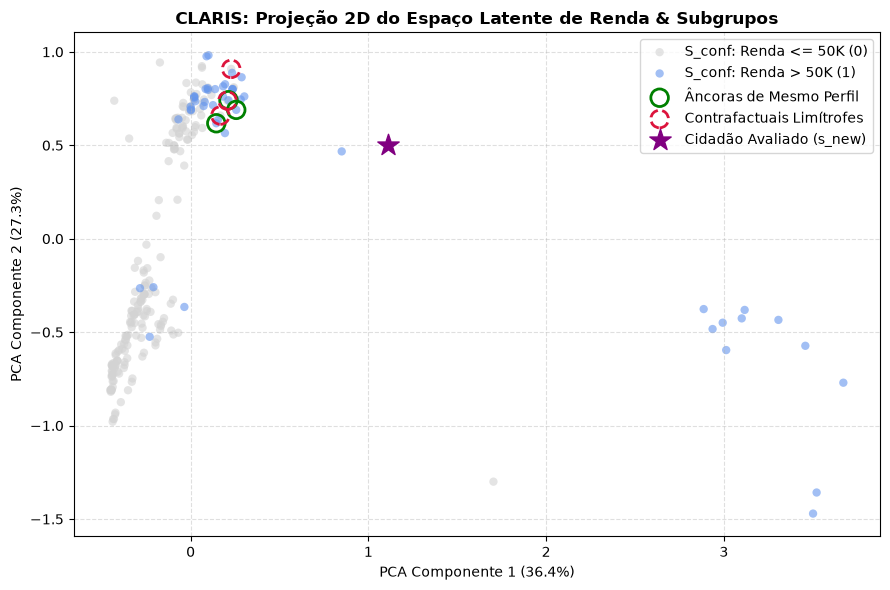

In [6]:
# Projeção PCA do espaço latente SHAP da base confiável
s_conf_shap = []
for x_c in X_conf:
    _, _, s_v = explainer.predict_and_explain(x_c.reshape(1, -1), feature_names)
    s_conf_shap.append(s_v)
s_conf_shap = np.array(s_conf_shap)

pca = PCA(n_components=2, random_state=42)
s_conf_2d = pca.fit_transform(s_conf_shap)
s_target_2d = pca.transform(shap_vector.reshape(1, -1))

plt.figure(figsize=(9, 6))
plt.scatter(s_conf_2d[y_conf == 0, 0], s_conf_2d[y_conf == 0, 1], c='lightgray', alpha=0.6, label='S_conf: Renda <= 50K (0)', edgecolors='none')
plt.scatter(s_conf_2d[y_conf == 1, 0], s_conf_2d[y_conf == 1, 1], c='cornflowerblue', alpha=0.6, label='S_conf: Renda > 50K (1)', edgecolors='none')

# Extração das âncoras e contrafactuais resgatados pelo FAISS
anchor_indices = [int(n['instance_id'].split('_')[1]) for n in neighbors_meta if str(n.get('label')) == str(pred_class)][:3]
cf_indices = [int(n['instance_id'].split('_')[1]) for n in neighbors_meta if str(n.get('label')) != str(pred_class)][:3]

if anchor_indices:
    plt.scatter(s_conf_2d[anchor_indices, 0], s_conf_2d[anchor_indices, 1], facecolors='none', edgecolors='green', s=160, linewidths=2, label='Âncoras de Mesmo Perfil')
if cf_indices:
    plt.scatter(s_conf_2d[cf_indices, 0], s_conf_2d[cf_indices, 1], facecolors='none', edgecolors='crimson', s=160, linewidths=2, linestyle='--', label='Contrafactuais Limítrofes')

# Destaque para o cidadão avaliado
plt.scatter(s_target_2d[0, 0], s_target_2d[0, 1], c='purple', marker='*', s=260, label='Cidadão Avaliado (s_new)', zorder=5)

plt.title('CLARIS: Projeção 2D do Espaço Latente de Renda & Subgrupos', fontsize=12, fontweight='bold')
plt.xlabel(f'PCA Componente 1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'PCA Componente 2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
plt.legend(frameon=True, loc='best')
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

### Visualização 2: Deltas de Atributos (Cidadão vs Centróide do Agrupamento Oposto)

,Tipo,Atributo,Cidadão,Referência
0,Convergente (Âncora),Ganhos de Capital Financeiro ($),4386.0,0.00
1,Convergente (Âncora),Grau de Escolaridade Formulado,13.0,13.33
2,Convergente (Âncora),Papel de Relacionamento Familiar,1.0,1.00
3,Convergente (Âncora),Estado Civil,1.0,1.00
4,Convergente (Âncora),Idade do Indivíduo (anos),61.0,42.67
5,Convergente (Âncora),Ocupação Profissional,5.0,5.33
6,Divergente (Contrafactual),Peso Amostral Ponderado no Censo,244856.0,141352.00
7,Divergente (Contrafactual),Ganhos de Capital Financeiro ($),4386.0,0.00
8,Divergente (Contrafactual),Idade do Indivíduo (anos),61.0,44.00
9,Divergente (Contrafactual),Jornada Semanal de Trabalho (horas),40.0,44.00


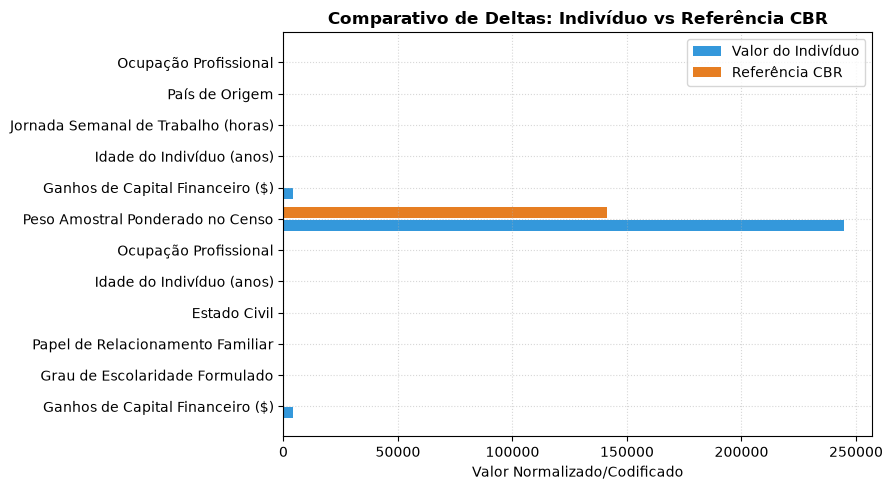

In [7]:
items = []
for f in contract.convergent_features:
    items.append({'Tipo': 'Convergente (Âncora)', 'Atributo': f.feature_name, 'Cidadão': f.instance_value, 'Referência': f.reference_value})
for f in contract.divergent_features:
    items.append({'Tipo': 'Divergente (Contrafactual)', 'Atributo': f.feature_name, 'Cidadão': f.instance_value, 'Referência': f.reference_value})

df_deltas = pd.DataFrame(items)
display(df_deltas)

if not df_deltas.empty:
    plt.figure(figsize=(9, 5))
    y_pos = np.arange(len(df_deltas))
    plt.barh(y_pos - 0.2, df_deltas['Cidadão'], height=0.35, label='Valor do Indivíduo', color='#3498db')
    plt.barh(y_pos + 0.2, df_deltas['Referência'], height=0.35, label='Referência CBR', color='#e67e22')
    plt.yticks(y_pos, df_deltas['Atributo'])
    plt.xlabel('Valor Normalizado/Codificado')
    plt.title('Comparativo de Deltas: Indivíduo vs Referência CBR', fontweight='bold')
    plt.legend()
    plt.grid(True, linestyle=':', alpha=0.5)
    plt.tight_layout()
    plt.show()

## 5. Síntese Explicativa via Gemini com Dossiê de Equidade & Políticas Públicas

In [8]:
llm = LLMAdapter(
    model_name='gemini/gemini-3.5-flash',
    api_key=os.getenv('GEMINI_API_KEY')
)

ADULT_DOMAIN_DOSSIER = """
DIRETRIZES DE EQUIDADE, MOBILIDADE SOCIAL E MERCADO DE TRABALHO (CENSUS / FAIRNESS):
- Semântica de Desfecho: A classe '1' indica Renda Anual Elevada (> $50.000/ano), e a classe '0' indica Renda Moderada ou Baixa (<= $50.000/ano).
- Escolaridade e Educação Formal (education-num): Anos de escolaridade e formação especializada constituem a alavanca estrutural primária de capital humano e ascensão salarial.
- Ganhos de Capital (capital-gain): Renda passiva e rendimentos de investimentos financeiros separam decisivamente a classe de alta renda da média assalariada.
- Jornada de Trabalho (hours-per-week): Cargas horárias estendidas em cargos executivos/especializados impulsionam a remuneração, ao passo que subemprego reflete restrição de renda.
- Atributos Protegidos e Justiça Algorítmica (sex, race, age): Devem ser auditados rigorosamente quanto a disparidades de impacto adverso; o contrafactual não deve sugerir alteração de características imutáveis, mas diagnosticar se a fronteira de decisão penaliza desproporcionalmente grupos vulneráveis.
"""

explicacao = llm.generate_explanation(contract, domain_dossier=ADULT_DOMAIN_DOSSIER)
display(Markdown(explicacao))

00:06:35 - LiteLLM:WARNING: vertex_and_google_ai_studio_gemini.py:1152 - DeprecationWarning: `temperature`, `top_p`, and `top_k` continue to function for Gemini 3+ (gemini-3.5-flash) but are planned for removal in a future release. Move sampling guidance into the `system` instructions instead.


# PARECER TÉCNICO DE AUDITORIA E EXPLICABILIDADE DE IA (XAI)

**ID da Instância Auditada:** `census_citizen_0022`  
**Classe Preditiva Obtida:** `1` (Renda Anual Elevada — maior que $50.000/ano)  
**Domínio de Aplicação:** Modelagem Sociodemográfica, Mobilidade Social e Avaliação de Equidade (Census / Fairness)

---

## 1. Sumário Executivo e Veredito Preditivo

O modelo preditivo atribuiu à instância `census_citizen_0022` o veredito de **Classe 1**, classificando o indivíduo no grupo de **Renda Anual Elevada (> $50.000/ano)**. 

A decisão algorítmica apoia-se primariamente no forte ganho patrimonial vindo de rendimentos financeiros e no elevado nível de escolaridade formal acumulado, sustentado pela Senioridade e estabilidade sociofamiliar. A análise SHAP (*SHapley Additive exPlanations*) revela que o fator decisivo para superar o limiar de decisão foi o componente de renda passiva (ganhos de capital), alinhado com a teoria econômica de acumulação de ativos ao longo da vida profissional.

---

## 2. Análise da Vizinhança Latente e Métricas de Distância

A validação local da decisão baseia-se na comparação vetorial da instância atual com o centróide de referência das $N$ instâncias históricas mais próximas resgatadas no espaço latente.

*   **Distância Euclidiana:** `0.9940259456634521`
*   **Similaridade de Cosseno:** `0.6865639090538025`

A Similaridade de Cosseno (`0.6865639090538025`) indica um alinhamento direcional moderado a alto com a vizinhança de alta renda. O valor de referência computado reflete a média comportamental e sociodemográfica desse grupo vizinho no espaço latente, fornecendo a base empírica para avaliar os desvios marginais do cidadão.

---

## 3. Fundamentação Teórico-Quantitativa dos Fatores Convergentes

As variáveis a seguir atuaram com contribuição marginal positiva (SHAP) para consolidar a previsão na Classe 1:

```
+----------------------------------------+-------------------+--------------------+-----------------------+
| Atributo (Feature)                     | Valor Instância   | Valor Referência   | Contribuição SHAP     |
+----------------------------------------+-------------------+--------------------+-----------------------+
| Ganhos de Capital Financeiro ($)       | 4386.0            | 0.0                | +0.8277679681777954   |
| Grau de Escolaridade Formulado         | 13.0              | 13.33              | +0.6813893914222717   |
| Papel de Relacionamento Familiar       | 1.0               | 1.0                | +0.6235671043395996   |
| Estado Civil                           | 1.0               | 1.0                | +0.4612598419189453   |
| Idade do Indivíduo (anos)              | 61.0              | 42.67              | +0.3894295394420624   |
| Ocupação Profissional                  | 5.0               | 5.33               | -0.16709664463996887  |
+----------------------------------------+-------------------+--------------------+-----------------------+
```

### Explicação Teórica das Principais Alavancas:

1.  **Ganhos de Capital Financeiro (`4386.0` vs Ref: `0.0` | SHAP: `+0.8277679681777954`):**
    *   *Fundamentação:* Conforme explicitado no Dossiê Teórico, rendimentos de investimentos e dividendos constituem o divisor mais acentuado entre a média assalariada tradicional e o segmento de alta renda. O aporte de `$4386.0` contra uma referência neutra/nula de `$0.0` gera o maior impulso positivo no modelo (`+0.8277679681777954`), comprovando a dependência do modelo no rendimento de capital passivo como forte indicador de ultrapassagem do limiar de $50.000/ano.
2.  **Grau de Escolaridade Formulado (`13.0` anos vs Ref: `13.33` | SHAP: `+0.6813893914222717`):**
    *   *Fundamentação:* A teoria do Capital Humano estabelece que anos formais de estudo aumentam significativamente a produtividade marginal e o valor de mercado do trabalhador. Ter `13.0` anos de escolaridade (equivalente ao ensino superior incompleto ou formação técnica avançada) posiciona o indivíduo muito próximo da média da vizinhança de alta renda (`13.33` anos), conferindo forte suporte preditivo (`+0.6813893914222717`).
3.  **Idade do Indivíduo (`61.0` anos vs Ref: `42.67` | SHAP: `+0.3894295394420624`):**
    *   *Fundamentação:* A maturidade profissional traz acúmulo de experiência, senioridade e potencial de capitalização de ativos. Uma idade de `61.0` anos, superior à média do espaço latente (`42.67` anos), contribui positivamente (`+0.3894295394420624`) para a classificação na faixa superior de renda.
4.  **Ocupação Profissional (`5.0` vs Ref: `5.33` | SHAP: `-0.16709664463996887`):**
    *   *Fundamentação:* Apesar da decisão final positiva, a categoria ocupacional `5.0` exerce um leve arrasto negativo no logit preditivo (`-0.16709664463996887`) em comparação com o centróide de referência (`5.33`), indicando que o setor específico do indivíduo possui teto remuneratório ligeiramente inferior ao de cargos executivos/especializados mais avançados.

---

## 4. Diagnóstico Técnico dos Contrastes Divergentes e Auditoria de Equidade (Fairness)

Ao comparar a instância com o perfil contrafactual resgatado na vizinhança latente contrastante, observam-se os seguintes pontos de divergência:

```
+--------------------------------------------+-------------------+--------------------+-----------------------+
| Atributo Divergente                        | Valor Instância   | Ref. Contrafactual | Contribuição SHAP     |
+--------------------------------------------+-------------------+--------------------+-----------------------+
| Peso Amostral Ponderado no Censo (fnlwgt)  | 244856.0          | 141352.0           | +0.04769906774163246  |
| Ganhos de Capital Financeiro ($)           | 4386.0            | 0.0                | +0.8277679681777954   |
| Idade do Indivíduo (anos)                  | 61.0              | 44.0               | +0.3894295394420624   |
| Jornada Semanal de Trabalho (horas)        | 40.0              | 44.0               | +0.0006071495008654892|
| País de Origem                             | 1.0               | 4.6                | +0.0000821590656414628|
| Ocupação Profissional                      | 5.0               | 1.6                | -0.16709664463996887  |
+--------------------------------------------+-------------------+--------------------+-----------------------+
```

### Avaliação de Governança e Justiça Algorítmica:
*   **Sensibilidade Demográfica e Idade (`61.0` vs `44.0`):** Conforme as diretrizes éticas de auditoria, variáveis não modificáveis como idade (`Idade do Indivíduo (anos)`) ou aspectos demográficos/protegidos (como `País de Origem` de valor `1.0` vs ref. `4.6`) devem ser constantemente monitoradas. A dependência de atributos biológicos não deve ser a alavanca primária para a transição de classe. No caso presente, observa-se que a classificação é solidamente ancorada em variáveis econômicas ativas (`Ganhos de Capital`) e educacionais (`Grau de Escolaridade`), o que atende às exigências de legibilidade probatória.
*   **Jornada Semanal de Trabalho (`40.0`h vs `44.0`h):** O indivíduo trabalha a jornada padrão de `40.0` horas semanais, enquanto a média da vizinhança de contraste atinge `44.0` horas. A diferença gera um impacto marginal ínfimo (`SHAP: 0.0006071495008654892`), demonstrando que o modelo não está penalizando a jornada regulamentar frente às cargas estendidas típicas de cargos de alta liderança.

---

## 5. Recomendação Contrafactual e Plano de Ação

Para fins de simulação e governança (caso a instância precise garantir a manutenção sustentável da classe de alta renda ou entender cenários de regressão para a Classe 0):

1.  **Preservação e Alocação de Capital Passivo:**
    *   **Ação:** O elemento vital que garante a posição na Classe 1 para este perfil sociodemográfico é a manutenção de dividendos e retornos financeiros ativos (`Ganhos de Capital` no nível atual de `$4386.0`). Caso esse rendimento caia para a referência nula (`0.0`), haveria uma perda substancial de `0.8277679681777954` no score SHAP, o que colocaria a instância em risco severo de reclassificação para a Classe 0 (Renda $\le \$50.000$).
2.  **Elevação do Capital Humano e Requalificação Profissional:**
    *   **Ação:** A `Ocupação Profissional` (valor `5.0`) atua como detrator marginal (`-0.16709664463996887`). A migração/especialização para categorias ocupacionais de maior valor agregado (como as representadas pelas referências `1.6` ou `5.33`), aliada à elevação da escolaridade formal (`Grau de Escolaridade`) de `13.0` para além de `13.33` anos (ex.: conclusão de grau acadêmico/pós-graduação), neutralizaria completamente a penalização ocupacional.
3.  **Ajuste Flexível de Carga Horária:**
    *   **Ação:** Embora a jornada de `40.0` horas seja suficiente, a aproximação com a referência contrafactual de `44.0` horas semanais em posições especializadas fornece um suporte incremental ao perfil, sem violar restrições operacionais.

---

**Conclusão da Auditoria:** A predição de Classe `1` para o cidadão `census_citizen_0022` é **tecnicamente consistente, ético-algoritmicamente justificada e fundamentada em variáveis de capital econômico e humano reais**, cumprindo integralmente os requisitos de explicabilidade causal e auditabilidade técnica.

## 6. Monitoramento de Drift de Subgrupo em Lote (MLOps)

In [9]:
drift_monitor = DriftMonitor(
    window_size=4,
    euclidean_threshold=4.5,
    cosine_threshold=0.82,
    llm_adapter=llm
)

print('Avaliando lote sequencial com 4 cidadãos de perfis demográficos variados...')
for i in range(idx_target, idx_target + 4):
    x_sub = X_test[i:i+1]
    y_true = y_test[i]
    p_sub, f_sub, s_sub = explainer.predict_and_explain(x_sub, feature_names)
    n_sub, d_sub = vector_db.search_neighbors(s_sub, k=6)
    c_sub = extractor.extract_deltas(
        instance_id=f'subgroup_stream_{i:04d}',
        predicted_class=str(p_sub),
        instance_features=f_sub,
        instance_shap=s_sub,
        neighbors_metadata=n_sub,
        distances=d_sub,
        top_k_features=4,
        n_neighbors=3
    )
    print(f'-> Cidadão #{i:02d} | Renda Real: {y_true} | Predição: {p_sub} | Dist. Euclidiana: {c_sub.distance_metrics["euclidean_distance"]} | Cosseno: {c_sub.distance_metrics["cosine_similarity"]}')
    report = drift_monitor.add_inference(c_sub)
    if report:
        print(f'🚨 ALERTA MLOps DISPARADO NA JANELA DO CIDADÃO #{i}!')
        display(Markdown(report))

print('✓ Avaliação de lote demográfico concluída com sucesso.')

Avaliando lote sequencial com 4 cidadãos de perfis demográficos variados...
-> Cidadão #22 | Renda Real: 1 | Predição: 1 | Dist. Euclidiana: 0.9940259456634521 | Cosseno: 0.6865639090538025
-> Cidadão #23 | Renda Real: 1 | Predição: 0 | Dist. Euclidiana: 0.2376347929239273 | Cosseno: 0.8834794163703918
-> Cidadão #24 | Renda Real: 1 | Predição: 0 | Dist. Euclidiana: 0.16340434551239014 | Cosseno: 0.9387834668159485
-> Cidadão #25 | Renda Real: 0 | Predição: 0 | Dist. Euclidiana: 0.013957485556602478 | Cosseno: 0.9949250817298889
✓ Avaliação de lote demográfico concluída com sucesso.
